# 🌾 Proyecto Integrador U4: Optimización Inferencial del Rendimiento Agrícola y Eficiencia de Riego
**Materia:** Análisis y Exploración de Datos (INC-2505)[cite: 41]

En este cuaderno desarrollamos paso a paso el **Algoritmo General de Simulación de Telemetría** en **DuckDB** ($N=100$ parcelas), seguido del análisis de **Correlación y Regresión Lineal (OLS)**, la **Prueba t-Student** entre `Tratamiento_A` y `Tratamiento_B`, y las **4 gráficas ejecutivas** del tablero[cite: 35, 36, 37, 39, 43].

## Algoritmo General de Simulación de Telemetría (Paso a Paso)
Siguiendo el algoritmo del PDF:
1. Fijamos la semilla determinista `setseed(0.42)`[cite: 43].
2. Generamos `parcela_id` del `1` al `100`[cite: 43].
3. Simulamos `volumen_riego` uniforme entre `100.0` y `300.0` $\text{m}^3/\text{ha}$ (redondeado a 2 decimales)[cite: 43].
4. Simulamos `fertilizante_kg` uniforme entre `50.0` y `150.0` $\text{kg}/\text{ha}$ (redondeado a 2 decimales)[cite: 44].
5. Asignamos `tipo_tratamiento` (`Tratamiento_A` si probabilidad `< 0.50`, `Tratamiento_B` si `>= 0.50`)[cite: 44].
6. Calculamos `rendimiento_ton` con intercepto `5.0`, sensibilidad al riego `0.035`, sensibilidad al fertilizante `0.020`, bono de `+1.8` para `Tratamiento_B` y ruido aleatorio entre `-0.8` y `+0.8`[cite: 45].

In [10]:
# ==============================================================================
# ALGORITMO GENERAL DE SIMULACIÓN DE TELEMETRÍA (PASO A PASO) EN DUCKDB
# ==============================================================================

# 1. Importar librerías necesarias para simulación, estadística y gráficos
import duckdb                      # Base de datos analítica en memoria
import pandas as pd                # Manipulación de datos tabulares
import numpy as np                 # Cálculos numéricos
import matplotlib.pyplot as plt  # Gráficos base
import seaborn as sns            # Gráficos estadísticos
import statsmodels.api as sm     # Modelo de regresión lineal OLS y resumen estadístico
from scipy import stats            # Prueba t-Student y distribuciones estadísticas

# Configurar estilo visual de los gráficos
sns.set_theme(style="whitegrid")

# 2. Paso 1 del algoritmo: Conectar a DuckDB en memoria y fijar semilla 0.42
# Esto garantiza reproducibilidad idéntica en cualquier equipo
con = duckdb.connect(database=":memory:")
con.execute("SELECT setseed(0.42);")

# 3. Pasos 2 a 6 del algoritmo: Crear tabla de N = 100 parcelas con telemetría
con.execute("""
CREATE TABLE telemetria_parcelas AS
WITH base_parcelas AS (
    -- Paso 2: Generar secuencia consecutiva de parcela_id de 1 a 100
    SELECT
        i AS parcela_id,
        -- Paso 3: Volumen de riego uniforme continuo entre 100.0 y 300.0 m3/ha
        ROUND(100.0 + (random() * (300.0 - 100.0)), 2) AS volumen_riego,
        -- Paso 4: Fertilizante aplicado uniforme continuo entre 50.0 y 150.0 kg/ha
        ROUND(50.0 + (random() * (150.0 - 50.0)), 2) AS fertilizante_kg,
        -- Probabilidad uniforme [0, 1) para asignar tratamiento en el Paso 5
        random() AS prob_tratamiento,
        -- Ruido aleatorio uniforme entre -0.8 y +0.8 ton/ha para el Paso 6
        -0.8 + (random() * (0.8 - (-0.8))) AS ruido_aleatorio
    FROM generate_series(1, 100) AS t(i)
),
con_tratamiento AS (
    SELECT
        parcela_id,
        volumen_riego,
        fertilizante_kg,
        -- Paso 5: Asignar Tratamiento_A (< 0.50) o Tratamiento_B (>= 0.50)
        CASE
            WHEN prob_tratamiento < 0.50 THEN 'Tratamiento_A'
            ELSE 'Tratamiento_B'
        END AS tipo_tratamiento,
        -- Bono del tratamiento: +1.8 para Tratamiento_B, 0.0 para Tratamiento_A
        CASE
            WHEN prob_tratamiento < 0.50 THEN 0.0
            ELSE 1.8
        END AS efecto_tratamiento,
        ruido_aleatorio
    FROM base_parcelas
)
-- Paso 6: Calcular rendimiento_ton aplicando la ecuación físico-matemática:
-- 5.0 + (0.035 * riego) + (0.020 * fertilizante) + efecto_tratamiento + ruido
SELECT
    parcela_id,
    volumen_riego,
    fertilizante_kg,
    tipo_tratamiento,
    ROUND(
        5.0
        + (0.035 * volumen_riego)
        + (0.020 * fertilizante_kg)
        + efecto_tratamiento
        + ruido_aleatorio,
        2
    ) AS rendimiento_ton
FROM con_tratamiento
ORDER BY parcela_id;
""")

# 4. Extraer los datos limpios de DuckDB hacia un DataFrame de Pandas
df = con.execute("""
    SELECT
        parcela_id,
        volumen_riego,
        fertilizante_kg,
        tipo_tratamiento,
        rendimiento_ton
    FROM telemetria_parcelas
    WHERE volumen_riego IS NOT NULL
      AND fertilizante_kg IS NOT NULL
      AND rendimiento_ton IS NOT NULL
""").df()

# Mostrar resumen del dataset simulado
print(f"Registros cargados: {len(df)}")
print(df["tipo_tratamiento"].value_counts())
display(df.head(10))

Registros cargados: 100
tipo_tratamiento
Tratamiento_A    51
Tratamiento_B    49
Name: count, dtype: int64


,parcela_id,volumen_riego,fertilizante_kg,tipo_tratamiento,rendimiento_ton
0,1,249.44,94.18,Tratamiento_A,16.08
1,2,234.72,82.97,Tratamiento_A,14.08
2,3,220.78,98.71,Tratamiento_A,14.60
3,4,277.93,144.14,Tratamiento_B,18.99
4,5,219.30,70.25,Tratamiento_A,14.63
5,6,203.24,69.26,Tratamiento_A,13.87
6,7,252.34,125.40,Tratamiento_A,15.70
7,8,142.21,132.60,Tratamiento_A,13.23
8,9,248.63,121.66,Tratamiento_A,16.66
9,10,176.86,67.67,Tratamiento_B,14.87


## Análisis de Correlación y Modelo Predictivo OLS
Calculamos la **matriz de correlación de Pearson ($r$)** para identificar qué variable tiene mayor relación lineal con `rendimiento_ton`, y ajustamos un modelo de **Regresión Lineal Múltiple (OLS)** con `statsmodels` incluyendo intercepto ($\beta_0$) para evaluar $R^2$ ajustado, p-valores y residuos.

In [11]:
# ==============================================================================
# CORRELACIÓN DE PEARSON Y REGRESIÓN LINEAL MÚLTIPLE (OLS)
# ==============================================================================

# 1. Definir variables predictoras (X) y variable dependiente (Y)
X = df[["volumen_riego", "fertilizante_kg"]]
y = df["rendimiento_ton"]

# 2. Calcular la matriz de correlación de Pearson sobre variables numéricas
columnas_numericas = ["volumen_riego", "fertilizante_kg", "rendimiento_ton"]
matriz_corr = df[columnas_numericas].corr(method="pearson")
print("=== MATRIZ DE CORRELACIÓN DE PEARSON (r) ===")
display(matriz_corr.round(4))

# 3. Agregar constante (intercepto beta_0) a X y ajustar modelo OLS con statsmodels
X_ols = sm.add_constant(X)
modelo_ols = sm.OLS(y, X_ols).fit()

# 4. Imprimir el resumen estadístico completo del modelo OLS
print("\n=== RESUMEN DEL MODELO OLS ===")
print(modelo_ols.summary())

# 5. Guardar predicciones y residuos (Y_real - Y_predicho) en el DataFrame
df["rendimiento_pred"] = modelo_ols.predict(X_ols)
df["residuo"] = df["rendimiento_ton"] - df["rendimiento_pred"]

# Calcular RMSE (Error Cuadrático Medio Raíz) y R2 ajustado
rmse = np.sqrt(np.mean(df["residuo"] ** 2))
r2_adj = modelo_ols.rsquared_adj
print(f"\nR2 Ajustado: {r2_adj:.4f} ({r2_adj*100:.2f}% de variabilidad explicada)")
print(f"RMSE: {rmse:.4f} ton/ha")

=== MATRIZ DE CORRELACIÓN DE PEARSON (r) ===


,volumen_riego,fertilizante_kg,rendimiento_ton
volumen_riego,1.0000,0.1463,0.8722
fertilizante_kg,0.1463,1.0000,0.3661
rendimiento_ton,0.8722,0.3661,1.0000



=== RESUMEN DEL MODELO OLS ===
                            OLS Regression Results                            
Dep. Variable:        rendimiento_ton   R-squared:                       0.819
Model:                            OLS   Adj. R-squared:                  0.815
Method:                 Least Squares   F-statistic:                     219.2
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           1.04e-36
Time:                        23:12:12   Log-Likelihood:                -144.47
No. Observations:                 100   AIC:                             294.9
Df Residuals:                      97   BIC:                             302.8
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const     

## Prueba de Hipótesis Inferencial (t-Student de Dos Muestras Independientes)
Evaluamos si `Tratamiento_B` incrementa el rendimiento promedio respecto a `Tratamiento_A`[cite: 33, 49]:
- **Hipótesis nula ($H_0$):** $\mu_B - \mu_A \le 0$[cite: 37, 49]
- **Hipótesis alternativa ($H_1$):** $\mu_B - \mu_A > 0$ (prueba unilateral derecha, nivel $\alpha = 0.05$)[cite: 37, 49]

Calculamos el estadístico $t$, el valor $p$, el **intervalo de confianza al 95%** para la diferencia de medias y el veredicto técnico[cite: 37, 49].

In [12]:
# ==============================================================================
# PRUEBA T-STUDENT INDEPENDIENTE E INTERVALO DE CONFIANZA AL 95%
# ==============================================================================

# 1. Separar el rendimiento por cada grupo de tratamiento
grupo_a = df[df["tipo_tratamiento"] == "Tratamiento_A"]["rendimiento_ton"]
grupo_b = df[df["tipo_tratamiento"] == "Tratamiento_B"]["rendimiento_ton"]

# 2. Ejecutar prueba t de dos muestras independientes (unilateral: B > A)
t_stat, p_val_unilateral = stats.ttest_ind(grupo_b, grupo_a, equal_var=False, alternative="greater")

# 3. Calcular diferencia de medias y error estándar para IC del 95%
diff_medias = grupo_b.mean() - grupo_a.mean()
n_a, n_b = len(grupo_a), len(grupo_b)
var_a, var_b = grupo_a.var(ddof=1), grupo_b.var(ddof=1)
se_diff = np.sqrt((var_a / n_a) + (var_b / n_b))

# Grados de libertad de Welch-Satterthwaite
gl = ((var_a / n_a + var_b / n_b) ** 2) / (
    ((var_a / n_a) ** 2) / (n_a - 1) + ((var_b / n_b) ** 2) / (n_b - 1)
)
t_crit = stats.t.ppf(0.975, df=gl)
margen_error = t_crit * se_diff
ic_95_inf = diff_medias - margen_error
ic_95_sup = diff_medias + margen_error

# 4. Mostrar resultados y veredicto frente a alfa = 0.05
alpha = 0.05
print(f"Media Tratamiento_A (n={n_a}): {grupo_a.mean():.2f} ton/ha")
print(f"Media Tratamiento_B (n={n_b}): {grupo_b.mean():.2f} ton/ha")
print(f"Diferencia de medias (B - A): {diff_medias:.2f} ton/ha")
print(f"IC 95% diferencia de medias: [{ic_95_inf:.2f}, {ic_95_sup:.2f}] ton/ha")
print(f"Estadístico t: {t_stat:.4f} | p-valor (unilateral): {p_val_unilateral:.6f}")

if p_val_unilateral < alpha:
    print("\nVEREDICTO: Se rechaza H0 (p < 0.05). Tratamiento_B incrementa significativamente el rendimiento.")
else:
    print("\nVEREDICTO: No se rechaza H0 (p >= 0.05). No hay evidencia suficiente de incremento.")

Media Tratamiento_A (n=51): 14.02 ton/ha
Media Tratamiento_B (n=49): 15.90 ton/ha
Diferencia de medias (B - A): 1.87 ton/ha
IC 95% diferencia de medias: [0.98, 2.77] ton/ha
Estadístico t: 4.1668 | p-valor (unilateral): 0.000034

VEREDICTO: Se rechaza H0 (p < 0.05). Tratamiento_B incrementa significativamente el rendimiento.


## Visualizaciones Clave y Métricas Resumen (KPIs)
Generamos las **4 gráficas** solicitadas en el proyecto en una cuadrícula $2 \times 2$[cite: 39, 50, 51, 52]:
1. **Heatmap de Correlación de Pearson**[cite: 39, 50]
2. **Dispersión con Línea de Regresión OLS** (`volumen_riego` vs. `rendimiento_ton`)[cite: 39, 50]
3. **Boxplot Comparativo de Tratamientos** (`Tratamiento_A` vs. `Tratamiento_B`)[cite: 40, 51]
4. **Histograma y Curva KDE de Residuos** (`Y_real - Y_predicho`)[cite: 40, 51]

=== KPIs PRINCIPALES ===
1. Rendimiento Promedio Global: 14.94 ton/ha
2. R2 Ajustado del Modelo OLS: 81.51%
3. p-valor Prueba t (B > A): 0.000034


/tmp/ipykernel_3576/426606735.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


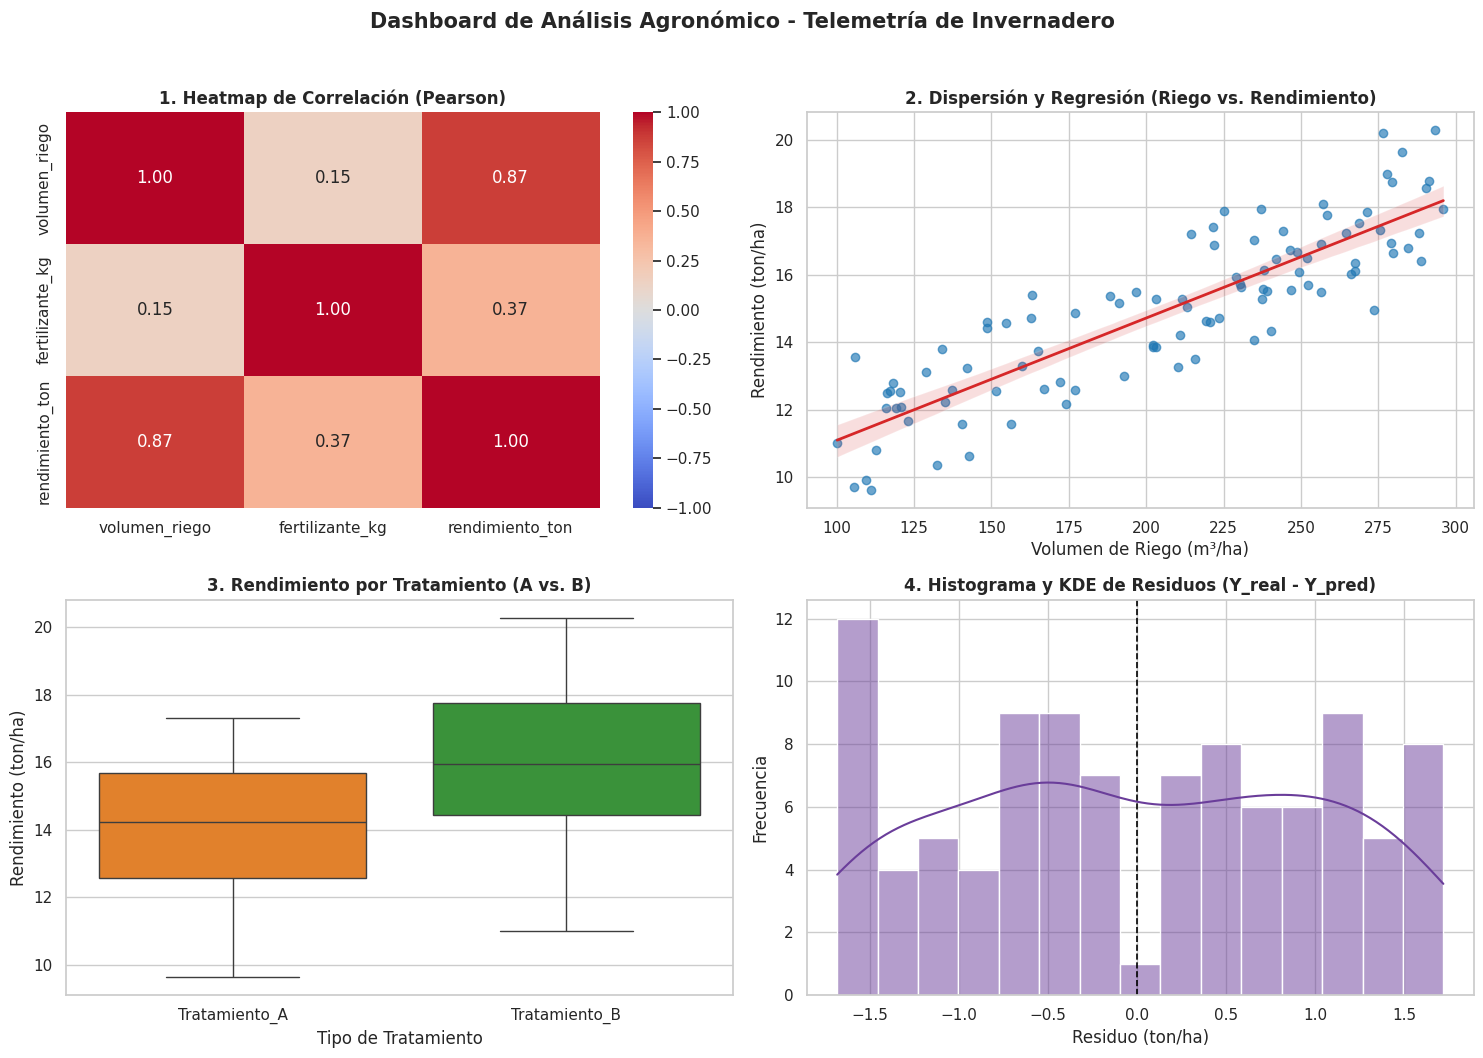

In [13]:
# ==============================================================================
# RESUMEN DE KPIs Y CUADRÍCULA DE 4 GRÁFICAS
# ==============================================================================

# 1. Imprimir tarjetas/métricas clave (KPIs)
print("=== KPIs PRINCIPALES ===")
print(f"1. Rendimiento Promedio Global: {df['rendimiento_ton'].mean():.2f} ton/ha")
print(f"2. R2 Ajustado del Modelo OLS: {r2_adj*100:.2f}%")
print(f"3. p-valor Prueba t (B > A): {p_val_unilateral:.6f}")

# 2. Crear figura con cuadrícula 2x2 para las 4 gráficas
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle("Dashboard de Análisis Agronómico - Telemetría de Invernadero", fontsize=15, fontweight="bold")

# --- Gráfica 1: Heatmap de Correlación de Pearson ---
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0, 0]
)
axes[0, 0].set_title("1. Heatmap de Correlación (Pearson)", fontweight="bold")

# --- Gráfica 2: Dispersión con Línea de Regresión OLS (Riego vs Rendimiento) ---
sns.regplot(
    data=df,
    x="volumen_riego",
    y="rendimiento_ton",
    scatter_kws={"alpha": 0.65, "color": "#1f77b4"},
    line_kws={"color": "#d62728", "linewidth": 2},
    ax=axes[0, 1]
)
axes[0, 1].set_title("2. Dispersión y Regresión (Riego vs. Rendimiento)", fontweight="bold")
axes[0, 1].set_xlabel("Volumen de Riego (m³/ha)")
axes[0, 1].set_ylabel("Rendimiento (ton/ha)")

# --- Gráfica 3: Boxplot Comparativo por Tratamiento ---
sns.boxplot(
    data=df,
    x="tipo_tratamiento",
    y="rendimiento_ton",
    palette={"Tratamiento_A": "#ff7f0e", "Tratamiento_B": "#2ca02c"},
    ax=axes[1, 0]
)
axes[1, 0].set_title("3. Rendimiento por Tratamiento (A vs. B)", fontweight="bold")
axes[1, 0].set_xlabel("Tipo de Tratamiento")
axes[1, 0].set_ylabel("Rendimiento (ton/ha)")

# --- Gráfica 4: Histograma y Densidad KDE de Residuos ---
sns.histplot(
    df["residuo"],
    kde=True,
    bins=15,
    color="#6a3d9a",
    ax=axes[1, 1]
)
axes[1, 1].axvline(0, color="black", linestyle="--", linewidth=1.2)
axes[1, 1].set_title("4. Histograma y KDE de Residuos (Y_real - Y_pred)", fontweight="bold")
axes[1, 1].set_xlabel("Residuo (ton/ha)")
axes[1, 1].set_ylabel("Frecuencia")

plt.tight_layout(rect=[0, 0.02, 1, 0.96])
plt.show()

Gráfica 1 — Mapa de Calor de Correlación (Heatmap): Es como una "tabla de pistas" con colores y números del -1 al 1 para medir qué tan pegado va un dato con otro. Si ves un número alto y positivo (cerca de 1) entre el riego o el fertilizante y el rendimiento, significa que cuando sube ese insumo, la cosecha también tiende a subir. Te ayuda a notar rápido qué factor pesa más en el rendimiento del cultivo.   


Gráfica 2 — Dispersión con Línea de Regresión OLS: Cada punto es una parcela del invernadero: a la derecha hay más agua de riego y más arriba hay mayor cosecha. La línea que cruza los puntos muestra la tendencia general del modelo y la franja sombreada alrededor es su margen de incertidumbre. Si la línea va hacia arriba, confirma que regar más se asocia con un mayor rendimiento.  


 Gráfica 3 — Diagrama de Cajas Comparativo (Boxplot): Aquí ponemos frente a frente al Tratamiento_A (el estándar) y al Tratamiento_B (el bio-estimulante nuevo). La línea dentro de cada caja es la mediana (el valor central), la caja encierra la mitad de las parcelas de ese grupo, los bigotes muestran el rango general y los puntos sueltos son casos raros (outliers). Si la caja del Tratamiento_B está más arriba que la del A, es una señal visual clara de que el bio-estimulante rinde más, respaldando la prueba t.


 Gráfica 4 — Histograma y Curva KDE de Residuos: Un residuo es simplemente qué tanto se equivocó el modelo en una parcela (rendimiento real menos rendimiento predicho). Las barras y la curva muestran si la mayoría de esos errores se amontonan cerca de 0 con forma de campana simétrica. Si se ve así, significa que el modelo no tiene sesgos graves y que sus errores se comportan de forma natural.  